# 03 — Execute the controlled pilot

This notebook runs the actual shared experiment code. It uses saved CALCE inputs, **100 evaluations including 20 shared initial points**, and local CPU computation. A completed run is reused only after its configuration/provenance key, file checksums, evaluation count and best recorded loss are verified. Failed attempts remain in separate directories.

The full main study is configured separately and is **not** launched by this notebook. See the resolved grid below before executing the run cell.

In [1]:
from pathlib import Path
import os, json, sys
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src/bo_vs_es").exists())
os.environ.setdefault("MPLCONFIGDIR", str(ROOT / "artifacts/.matplotlib"))
os.environ.setdefault("OMP_NUM_THREADS", "1")
os.environ.setdefault("OPENBLAS_NUM_THREADS", "1")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from bo_vs_es.analysis.study import save_figure
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.max_columns", 15)
print("Repository:", ROOT)
print("Python:", sys.version.split()[0])


Repository: /Users/mihirsinha/Downloads/repo/Dsa4212-final-project-bayesian-vs-evolutionary
Python: 3.13.6


/Users/mihirsinha/Downloads/repo/Dsa4212-final-project-bayesian-vs-evolutionary/.venv/lib/python3.13/site-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


In [2]:
from bo_vs_es.experiments.runner import jobs_for, run_collection
recipe=json.loads((ROOT/"configs/experiments/pilot.json").read_text())
protocol=json.loads((ROOT/recipe["protocol"]).read_text())
jobs=pd.DataFrame(jobs_for(recipe))
display(jobs.groupby(["block","objective","domain","budget"],dropna=False).size().rename("runs").reset_index())
print("Total pilot runs:",len(jobs),"; maximum search evaluations:",int(jobs.budget.sum()))
display(pd.Series(protocol["bo"],name="BO settings"))
display(pd.Series(protocol["cma"],name="CMA settings"))

,block,objective,domain,budget,runs
0,battery_ball,battery,ball,100,30
1,battery_boundary,battery,box,100,14
2,ocv_sensitivity,battery,ball,100,10
3,quadratic_control,quadratic,ball,100,30


Total pilot runs: 84 ; maximum search evaluations: 8400


fit_maxiter      60
acq_maxiter      80
raw_samples     256
num_restarts      8
Name: BO settings, dtype: int64

population                     8.0
sigma0                         0.3
max_proposals_per_point    10000.0
Name: CMA settings, dtype: float64

## What changes, and what stays fixed?
- Isotropic versus ARD BO changes the GP length-scale structure; both use Matérn-5/2 and stable analytic LogEI.
- Full versus diagonal CMA changes covariance structure. Population size, initial scale and all explicitly set options are shared.
- Random search supplies a simple reference and uses the same initial observations.
- CMA starts at the best of the initial observations; BO uses the entire initial dataset. This utilisation difference is disclosed.
- The ball study contains three matched seeds. Boundary, OCV and synthetic controls have one seed and are demonstrations, not robust inferential evidence.
- The boundary experiment compares resampling and projection on the same full physical box. Both are geometrically consistent, so an additional rotation effect is not guaranteed.

Every attempted simulator call consumes budget. A failed call terminates that run and is preserved. Geometric rejections consume decision time only. Held-out assessment consists of two extra, separately recorded simulator calls after search.

In [3]:
results=run_collection("configs/experiments/pilot.json")
display(results.groupby(["block","status"]).size().rename("runs").reset_index())
failures=results[results.status!="complete"]
if len(failures):
    display(failures[["run_id","method","error"]])
    raise RuntimeError("Pilot contains failed runs; inspect preserved errors before interpreting it")

[1/84] battery_ball bo_iso ball Q=None seed=0 none: complete (verified cached)


[2/84] battery_ball bo_ard ball Q=None seed=0 none: complete (verified cached)


[3/84] battery_ball cma_full ball Q=None seed=0 resample: complete (verified cached)


[4/84] battery_ball cma_diag ball Q=None seed=0 resample: complete (verified cached)


[5/84] battery_ball random ball Q=None seed=0 none: complete (verified cached)


[6/84] battery_ball bo_iso ball Q=None seed=1 none: complete (verified cached)


... (75 outputs left out)

[82/84] ocv_sensitivity cma_full ball Q=101 seed=0 resample: complete (verified cached)


[83/84] ocv_sensitivity cma_diag ball Q=101 seed=0 resample: complete (verified cached)


[84/84] ocv_sensitivity random ball Q=101 seed=0 none: complete (verified cached)


,block,status,runs
0,battery_ball,complete,30
1,battery_boundary,complete,14
2,ocv_sensitivity,complete,10
3,quadratic_control,complete,30


## Inspect one complete input/output trace
The trace contains the optimiser coordinate `z`, base coordinate `u`, physical parameter vector `theta`, objective value and call timing. Initial and adaptive evaluations are separately identified. The recommendation is the lowest observed deterministic calibration loss, not the final proposed point.

In [4]:
row=results[(results.block=="battery_ball")&(results.method=="bo_ard")&(results.seed==0)&(results.rotation_seed==101)].iloc[0]
run=ROOT/row.run_path
trace=pd.read_csv(run/"evaluations.csv")
print("Run ID:",row.run_id)
display(trace[["evaluation","phase","u","theta","loss","objective_s"]].iloc[[0,19,20,-1]])
display(pd.Series(json.loads((run/"recommendation.json").read_text())))
assert len(trace)==100 and trace.status.eq("ok").all()
print("The full manifest, initial design, proposals and diagnostics are in:",run.relative_to(ROOT))

Run ID: aadc3c141350e396


,evaluation,phase,u,theta,loss,objective_s
0,1,initial,"[0.1397175458879698, -0.14680135880152617, 0.7...","[0.02047680194951157, 0.0025598655361937592, 6...",0.005151,0.001379
19,20,initial,"[0.3822764822673338, 0.05967326628906582, -0.2...","[0.03893407167043061, 0.005610565266804047, 19...",0.003094,0.001367
20,21,search,"[0.8956515396647463, 0.3470075701640217, -0.26...","[0.151696488247866, 0.01672076706247814, 16.33...",0.006295,0.001325
99,100,search,"[0.6517687804765022, 0.6296096420074547, 0.355...","[0.07950322664452579, 0.04894351485045611, 172...",0.000046,0.001323


rule             lowest observed deterministic calibration loss
evaluation                                                   65
z             [-0.596712, 0.177388, 0.158026, 0.766466, 0.00...
u              [0.642341, 0.526113, 0.43229, 0.327892, 0.12734]
loss                                                   0.000034
theta         [0.077542, 0.033027, 231.215246, 0.015549, 72....
assessment    {'fuds80_rmse_v': 0.007320529631637995, 'fuds5...
dtype: object

The full manifest, initial design, proposals and diagnostics are in: artifacts/pilot_v1/aadc3c141350e396


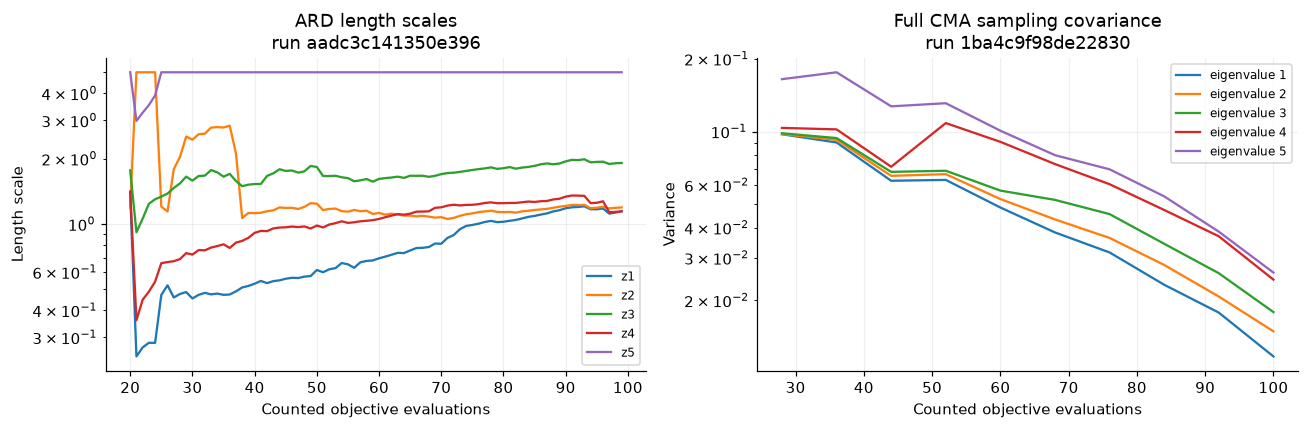

,run_id,method,seed,rotation_seed,handler,best_loss,rejected_fraction,repaired_fraction,search_s
30,73096dea4da538b6,bo_iso,0,NaN,none,0.000121,0.000000,0.0000,14.088502
31,3281134a69830ec3,bo_ard,0,NaN,none,0.000166,0.000000,0.0000,14.133392
32,f3665ae77b12d2e4,cma_full,0,NaN,resample,0.000306,0.130435,0.0000,0.154586
33,d1c2f5f6b99d6236,cma_full,0,NaN,project,0.000072,0.000000,0.1625,0.152905
34,17bfb0df37d93c1d,cma_diag,0,NaN,resample,0.000081,0.036145,0.0000,0.153427
35,0bb4a358a035f823,cma_diag,0,NaN,project,0.000141,0.000000,0.1000,0.153000
36,8ab8cdfc29c9111e,random,0,NaN,none,0.000279,0.000000,0.0000,0.143794
37,d5961f4839b096ea,bo_iso,0,101.0,none,0.000121,0.000000,0.0000,13.861387
38,0b91705d864d8b4e,bo_ard,0,101.0,none,0.000416,0.000000,0.0000,14.109126
39,8441a4ee25960585,cma_full,0,101.0,resample,0.000146,0.069767,0.0000,0.160549


In [5]:
from bo_vs_es.analysis.study import diagnostic_figure, boundary_table
fig=diagnostic_figure(results); save_figure(fig,"pilot_internal_diagnostics"); plt.show()
display(boundary_table(results))

## Synthetic controls and OCV sensitivity
The synthetic quadratic minimum is known to be zero; only there is objective value equal to simple regret. Its condition number is changed independently of the coordinate rotation.

The OCV sensitivity block removes only the fixed calibration-rest offset. It retains the data, parameter ranges, optimisation settings and matched initial designs. This checks one OCV assumption; it does not cover all inter-cell or SOC uncertainty.

In [6]:
quadratic=results[results.block=="quadratic_control"]
display(quadratic.pivot_table(index=["condition","method"],columns=quadratic.rotation_seed.fillna(-1),values="best_loss"))
corrected=results[(results.block=="battery_ball")&(results.seed==0)]
uncorrected=results[results.block=="ocv_sensitivity"]
sensitivity=uncorrected.merge(corrected,on=["method","seed","rotation_seed","domain","handler"],suffixes=("_uncorrected","_corrected"))
display(sensitivity[["method","rotation_seed","best_loss_corrected","best_loss_uncorrected","fuds80_rmse_v_corrected","fuds80_rmse_v_uncorrected"]])

rotation_seed         -1.0           101.0
condition method                          
1.0       bo_ard    0.000001  6.626493e-07
          bo_iso    0.000002  1.542545e-06
          cma_diag  0.002936  2.454766e-03
          cma_full  0.001456  2.080574e-03
          random    0.012708  1.270786e-02
100.0     bo_ard    0.000001  4.958439e-06
          bo_iso    0.000018  9.700270e-06
          cma_diag  0.003131  1.037548e-03
          cma_full  0.002625  2.183111e-03
          random    0.003542  3.541709e-03
10000.0   bo_ard    0.000002  5.461909e-05
          bo_iso    0.000092  1.944736e-04
          cma_diag  0.000330  7.019280e-04
          cma_full  0.001028  6.749499e-04
          random    0.001701  1.700653e-03

,method,rotation_seed,best_loss_corrected,best_loss_uncorrected,fuds80_rmse_v_corrected,fuds80_rmse_v_uncorrected
0,bo_iso,NaN,0.000022,0.000049,0.005874,0.005947
1,bo_ard,NaN,0.000038,0.000036,0.007341,0.006341
2,cma_full,NaN,0.000177,0.000119,0.010266,0.008201
3,cma_diag,NaN,0.000107,0.000041,0.007875,0.007961
4,random,NaN,0.000393,0.000177,0.019548,0.015442
5,bo_iso,101.0,0.000049,0.000038,0.006877,0.007312
6,bo_ard,101.0,0.000034,0.000033,0.007321,0.006058
7,cma_full,101.0,0.000106,0.000045,0.007758,0.005616
8,cma_diag,101.0,0.000170,0.000042,0.010778,0.008202
9,random,101.0,0.000393,0.000177,0.019548,0.015442


The results are ready for the analysis notebook. Completion of a small pilot is evidence that the experimental machinery works; it is not a sufficient basis for a universal algorithm ranking.